# Where a coding model decides its algorithm: Stage A full-state exchange (demo)

**Artifact** `art_rMlbrjVB1c__`: iteration 6 of *prompt bans substitute, not just subtract*. bf16 **Qwen3-8B** (rev `b968826d`, thinking off) on one 16 GB RTX 2000 Ada.

Qwen3-8B almost always writes one *default* algorithm per coding task. On **T2** (the length of the shortest path in a directed weighted graph) the default is **Dijkstra**. A one-sentence ban, *"Do not use Dijkstra's algorithm for this task."*, moves it to a substitute **Y = Bellman-Ford/SPFA**. The artifact asks **where in the prompt's internal states that choice is carried**.

**Method (Stage A).** Run the *neutral twin*: a prompt with exactly as many tokens as the ban that says something harmless (*"Do not use man and the house for this task."*). While the twin's prompt is processed, overwrite its residual-stream block outputs with the ban's, at chosen positions and blocks:

| cell | what is written into the twin |
|---|---|
| `BAN` | nothing: the full ban prompt itself (the effect to explain) |
| `X_0-11`, `X_12-23`, `X_24-35`, `X_0-35` | the ban's states at the **task-specification positions**, in one band of blocks |
| `COND` | the K/V cache of the **condition span**, the tokens where ban and twin differ (the "direct route") |
| `RPOS` | the ban's states at the **read position** (the last prompt token), all 36 blocks |
| `MR_0-35`, `MR_12-23` | control: a **matched-norm random** displacement of the twin's spec states |
| `PLACEBO` | control: the spec states of a **second neutral twin** |

Every arm of a CRN slot shares the slot's exact common random numbers. Each cell is therefore compared with the twin **slot by slot** (exact McNemar test).

**What this notebook runs.** `method.py` is a stage runner. Every stage is its own process, and the GPU stages need the 8B model and about 2.7 GPU-hours. This notebook:
1. shows `method.py` itself (the full run sits behind a flag);
2. shows the T2 prompts and the token positions that are exchanged;
3. reruns the code of the **analysis** stage (`src/stats6.py`, `src/analysis6.py::stage_a`) on **100 recorded, labelled programs** from the run (T2, all ten cells, ten paired slots);
4. reruns the **audit** stage's independent standard-library re-derivation (`audit/rederive.py`, Stage A part);
5. draws the **figures** stage's F1, plots the paired slots, and prints paired programs.

**Reported result (full run, N = 30 per cell).** On T2, exchanging the ban's spec states at all blocks (`X_0-35`) moves 24 of 30 slots from Dijkstra to Bellman-Ford/SPFA: transfer 0.80, McNemar 24:0, Holm p 7e-7. Blocks 12-23 carry most of it. The condition-span splice (`COND`) and the read position (`RPOS`) transfer 0.00. The controls stay low (MR ≤ 0.13, placebo ≤ 0.03).

The analysis takes seconds on a CPU; most of the wall time goes to package installation.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab (method.py logs through it): always install
_pip('loguru==0.7.3')

# numpy, pandas (needed by statsmodels), scipy, statsmodels, matplotlib -- pre-installed on Colab:
# install locally only, at Colab's exact versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py (original import block) ----
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# ---- src/stats6.py, src/analysis6.py, src/figures6.py and audit/rederive.py (their imports, merged) ----
import json
import math
import os
import random
from collections import Counter, defaultdict
from typing import Any

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize, stats

# ---- notebook addition: show tables and saved figures inline ----
from IPython.display import Image, Markdown, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-6/experiment-30/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
_ex = data["datasets"][0]["examples"]
print(data["metadata"]["description"])
print(f"dataset '{data['datasets'][0]['dataset']}': {len(_ex)} examples | cells "
      f"{dict(Counter(e['metadata_cell'] for e in _ex))} | slots {data['metadata']['slots']}")
print("model:", data["metadata"]["model"])

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
Curated demo subset of the Stage A full-state exchange (iteration 6, bf16 Qwen3-8B): task T2, all ten cells, ten paired CRN slots (first streams of every template), 100 labelled programs.
dataset 'stage_a_exchange': 100 examples | cells {'BAN': 10, 'X_0-11': 10, 'X_12-23': 10, 'X_24-35': 10, 'X_0-35': 10, 'COND': 10, 'RPOS': 10, 'MR_0-35': 10, 'MR_12-23': 10, 'PLACEBO': 10} | slots [0, 1, 2, 8, 9, 10, 16, 17, 23, 24]
model: Qwen/Qwen3-8B@b968826d9c46dd6066d109eabc6255188de91218 (bf16, thinking off, T = 1.0)


## Configuration

All tunable parameters are here. To move toward the original run:
- **`N_SLOTS`**: paired CRN slots per Stage A cell, taken from the demo data. `mini_demo_data.json` holds 10. The run used 30 per cell on six tasks.
- **`N_PERM`**: permutations in `audit/rederive.py`'s swap placebo (original: 2000).
- **`FULL_DATA`**: path to the artifact's `full_method_out.json`. When set, the analysis reruns on **all six tasks × 30 slots** (1,530 labelled programs) and reproduces the published Stage A tables. That file contains no program text.
- **`RUN_FULL_PIPELINE`**: runs `method.py`'s stages as subprocesses. This needs a checkout of the artifact repository with its `.venv` (`ARTIFACT_ROOT`). The GPU stages also need a 16 GB CUDA GPU (about 2.7 GPU-hours), and the label judges need `OPENROUTER_API_KEY`. `STAGES_TO_RUN = ["analysis", "figures", "audit"]` reruns only the CPU stages on the recorded rows.

In [5]:
# ---- demo scale (smallest working values: N_SLOTS = 2, N_PERM = 10; all run in well under a minute) ----
N_SLOTS = 10         # paired CRN slots per Stage A cell: all of mini_demo_data.json (original run: 30 per cell, 6 tasks)
N_PERM = 2000        # permutations of audit/rederive.py's swap placebo (= original)
FULL_DATA = None     # path to the artifact's full_method_out.json -> all 6 tasks x 30 slots (original scale)

# ---- method.py stage runner (artifact repository + its .venv; GPU stages: one 16 GB CUDA GPU) ----
RUN_FULL_PIPELINE = False     # True: run method.py's stages below as subprocesses
STAGES_TO_RUN = ["all"]       # or a subset of: prompts utest commit0 gpu ext lgpu label analysis novelty figures outputs audit
ARTIFACT_ROOT = "."           # folder holding the artifact's method.py, src/, scripts/ and audit/
GPU_DEADLINE_MIN = 175        # method.py: deadline of the main GPU queue in minutes (scripts/run_gpu_main.sh 175)
EXT_DEADLINE_MIN = 25         # method.py: deadline of the extension stage in minutes (src/gpu6.py ext --deadline-min 25)

DEMO_DIR = Path("demo_outputs")   # where this notebook's own analysis writes its results/ and figures/

## 1. The entry point: `method.py`

`method.py` runs the experiment as an ordered list of **stages**. Each stage runs in its own process, because the GPU holds one model at a time. Every stage is resumable and logs to `logs/`. The next three cells are `method.py`'s own code: logger setup, the stage table, and `main()`. Two fixes adapt it to a notebook. `ROOT` comes from `ARTIFACT_ROOT`, since a notebook has no `__file__`. The stage list comes from `STAGES_TO_RUN` instead of `sys.argv`.

| stage | what it does | needs |
|---|---|---|
| `prompts` | twin / ban / placebo / top-five-ban prompts and their token positions | CPU |
| `utest` | U1-U5 engine unit tests (identity exchange byte-exact, spec exchange = KV splice, ...) | GPU |
| `commit0` | hash-commit every decision rule before any decisive sample | CPU |
| `gpu` | twins, **Stage A**, ST noise-site grid, S3 vs KL-matched temperature, top-five push | GPU (175 min deadline) |
| `ext` | forced "Implement Y" sources, semantic seed, held-out W4 template | GPU |
| `lgpu` | teacher-forced opening rankings for the landing-forecast contest L | GPU |
| `label` | frozen labellers: runtime tracer + AST, with a blind judge on disagreement | CPU + OpenRouter |
| `analysis` | every statistic (`src/analysis6.py`, `src/stats6.py`) + L scoring | CPU: **Stage A rerun below** |
| `novelty` | novelty audit of the correct 'other' programs | OpenRouter |
| `figures` | F1-F6 | CPU: **F1 rerun below** |
| `outputs` | CPU tests, bookkeeping, `method_out.json` | CPU |
| `audit` | independent stdlib re-derivation of every headline, with placebos | CPU: **Stage A part rerun below** |

In [6]:
ROOT = Path(ARTIFACT_ROOT).resolve()   # method.py: ROOT = Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG");

In [7]:
STAGES = {
    "prompts": [[PY, "src/prompts6.py"]],                                 # STEP 0-1 (CPU): prompts, positions, dep
    "utest": [[PY, "src/gpu6.py", "utest"]],                              # STEP 2 (GPU): U1-U5
    "commit0": [[PY, "src/prereg6.py"]],                                  # commit #0 before any decisive sample
    "gpu": [["bash", "scripts/run_gpu_main.sh", str(GPU_DEADLINE_MIN)]],  # STEPS 4-8 (GPU, deadline in minutes)
    "ext": [[PY, "src/gpu6.py", "ext", "--deadline-min", str(EXT_DEADLINE_MIN)]],  # STEP 9 extensions (forced, seed, W4)
    "label": [[PY, "src/label6.py"]],                                     # STEP 10 (CPU worker; follows the GPU)
    "lgpu": [[PY, "src/lcontest.py", "events"], [PY, "src/lcontest.py", "open"]],  # STEP 3 (L teacher-forced)
    "analysis": [[PY, "src/analysis6.py"], [PY, "src/lcontest.py", "score"]],
    "novelty": [[PY, "src/novelty6.py"]],
    "figures": [[PY, "src/figures6.py"]],
    "outputs": [[PY, "src/bookkeeping6.py"], [PY, "src/outputs6.py"]],
    "audit": [["python3", "-I", "audit/rederive.py"]],
}
ORDER = ["prompts", "utest", "commit0", "gpu", "ext", "lgpu", "label", "analysis", "novelty", "figures", "outputs",
         "audit"]

for _st in ORDER:   # notebook addition: print the pipeline in run order
    print(f"{_st:9s}", "  &&  ".join(" ".join(".venv/bin/python" if c == PY else c for c in cmd) for cmd in STAGES[_st]))

prompts   .venv/bin/python src/prompts6.py
utest     .venv/bin/python src/gpu6.py utest
commit0   .venv/bin/python src/prereg6.py
gpu       bash scripts/run_gpu_main.sh 175
ext       .venv/bin/python src/gpu6.py ext --deadline-min 25
lgpu      .venv/bin/python src/lcontest.py events  &&  .venv/bin/python src/lcontest.py open
label     .venv/bin/python src/label6.py
analysis  .venv/bin/python src/analysis6.py  &&  .venv/bin/python src/lcontest.py score
novelty   .venv/bin/python src/novelty6.py
figures   .venv/bin/python src/figures6.py
outputs   .venv/bin/python src/bookkeeping6.py  &&  .venv/bin/python src/outputs6.py
audit     python3 -I audit/rederive.py


In [8]:
@logger.catch(reraise=True)
def main() -> None:
    want = STAGES_TO_RUN or ["all"]   # method.py: want = sys.argv[1:] or ["all"]
    stages = ORDER if want == ["all"] else want
    for st in stages:
        for cmd in STAGES[st]:
            t0 = time.time()
            logger.info(f"stage {st}: {' '.join(cmd)}")
            if st == "label" and "all" in want:
                (ROOT / "results" / "gpu_all_done.flag").write_text("done\n")  # the GPU work above has finished
            r = subprocess.run(cmd, cwd=ROOT)
            logger.info(f"stage {st} exit {r.returncode} in {time.time() - t0:.0f}s")
            if r.returncode != 0:
                raise RuntimeError(f"stage {st} failed ({' '.join(cmd)})")


if RUN_FULL_PIPELINE:   # method.py: if __name__ == "__main__": main()
    main()
else:
    logger.info("RUN_FULL_PIPELINE = False: no stage subprocess is started; the cells below rerun the code of the "
                "'analysis', 'figures' and 'audit' stages on the recorded demo programs")

16:25:56|INFO   |RUN_FULL_PIPELINE = False: no stage subprocess is started; the cells below rerun the code of the 'analysis', 'figures' and 'audit' stages on the recorded demo programs


## 2. What the model reads: the T2 prompts and the exchanged positions (stage `prompts`)

Stage A uses three prompts per template:
- the **ban**: *"Do not use Dijkstra's algorithm for this task."* + the task;
- its **neutral twin**: a harmless condition of the *same token length*;
- a second neutral twin, the **placebo** source.

All three have identical token positions, so the state at position *p* of the ban can be written into position *p* of the twin. The positions come from `prompts/prompts6.jsonl` and follow the `src/cfg6.py` conventions:
- **SPEC** = `[p1, spec_end)`: from the first `Task:` token to the last user token. `X_b` exchanges here.
- **COND** = the span where ban and twin differ (the condition). `COND` splices its K/V cache.
- **R** = `P - 1`: the read position, where the first program token is sampled. `RPOS` exchanges here.

The cell below checks, for each of the four templates, that the three prompts have equal length and positions. It then prints the W1 ban and its twin with the spans marked. The token pieces were decoded with the Qwen3 tokenizer when the demo data was built.

In [9]:
# Notebook addition: the T2 prompt records of prompts/prompts6.jsonl with their positions
P6 = {(p["task"], p["w"], p["kind"]): p for p in data["metadata"]["prompts"]}


def mark(p: dict[str, Any]) -> str:
    """Prompt text with <<COND: ...>> around the condition span, [[SPEC: ...]] around the task spec, {R} before R."""
    (c0, c1), out = p["cond"], []
    for i, s in enumerate(p["pieces"]):
        out.append(("<<COND:" if i == c0 else "") + ("[[SPEC:" if i == p["p1"] else "") + ("{R}" if i == p["R"] else "")
                   + s + (">>" if i == c1 - 1 else "") + ("]]" if i == p["spec_end"] - 1 else ""))
    return "".join(out)


print("template  kind       P   p1  spec_end   R  cond       condition span")
for (t, w, kind), p in sorted(P6.items()):
    tw = P6[(t, w, "twin")]
    assert (p["P"], p["p1"], p["spec_end"], p["R"]) == (tw["P"], tw["p1"], tw["spec_end"], tw["R"]), "positions differ"
    print(f"{w:9s} {kind:8s} {p['P']:4d} {p['p1']:4d} {p['spec_end']:8d} {p['R']:4d}  {str(p['cond']):10s} "
          f"{''.join(p['pieces'][p['cond'][0]:p['cond'][1]])!r}")
for kind in ("ban", "twin"):
    print(f"\n===== T2 / W1 / {kind} =====")
    print(mark(P6[("T2", "W1", kind)]))

template  kind       P   p1  spec_end   R  cond       condition span
W1        ban       200   14      191  199  [6, 10]    " Dijkstra's algorithm"
W1        placebo   200   14      191  199  [6, 10]    ' guy and the house'
W1        twin      200   14      191  199  [6, 10]    ' man and the house'
W2        ban       200   14      191  199  [9, 13]    " Dijkstra's algorithm"
W2        placebo   200   14      191  199  [9, 13]    ' guy and the house'
W2        twin      200   14      191  199  [9, 13]    ' man and the house'
W3        ban       196   10      187  195  [4, 8]     " Dijkstra's algorithm"
W3        placebo   196   10      187  195  [4, 8]     ' guy and the house'
W3        twin      196   10      187  195  [4, 8]     ' man and the house'
W5        ban       202   16      193  201  [11, 15]   " Dijkstra's algorithm"
W5        placebo   202   16      193  201  [11, 15]   ' guy and the house'
W5        twin      202   16      193  201  [11, 15]   ' man and the house'

===== 

## 3. The intervention (stage `gpu`, `src/gpu6.py`): not run in this notebook

For each (task, template), the GPU stage first prefills the twin, the ban and the placebo. It **captures every block's output** at the SPEC, R and COND positions (`Prompt` with `cap_hooks`). Each Stage A cell is then a **modified twin prefill**, built with forward hooks on the decoder blocks (`engine_v4.block_hooks`). The core of `stage_twins_A` (condensed excerpt, names as in the source):

```python
def set_rows_edit(pos, src):
    """Exchange: overwrite block-l outputs at positions pos with src[l] (exact source values)."""
    def mk(l):
        def f(h):
            h = h.clone()
            h[0, pos] = src[l].to(h.dtype)
            return h
        return f
    return {l: mk(l) for l in src}

spec_pos = tw.idx[tw.iS]                                  # tw / bn / pl = twin / ban / placebo Prompt objects
for b, blocks in BANDS.items():                           # X_b: the ban's spec states in block band b
    pre_b = prefill6(model, tw.ids, edits=set_rows_edit(spec_pos, {l: bn.H[l][bn.iS] for l in blocks}))
# COND: twin prefill, then the condition span's K/V in every layer replaced by the ban's
K[:, :, tw.c0:tw.c1] = bn.pre["kv"][l][0][:, :, tw.c0:tw.c1]
V[:, :, tw.c0:tw.c1] = bn.pre["kv"][l][1][:, :, tw.c0:tw.c1]
# RPOS: the ban's states at the read position R, all 36 blocks
pre_r = prefill6(model, tw.ids, edits=set_rows_edit(tw.idx[tw.iR:tw.iR + 1], {l: bn.H[l][tw.iR:tw.iR + 1] for l in ALL_BLOCKS}))
# PLACEBO: a second neutral twin's spec states, all blocks
pre_p = prefill6(model, tw.ids, edits=set_rows_edit(spec_pos, {l: pl.H[l][pl.iS] for l in ALL_BLOCKS}))
# MR_b (mr_prefill): h <- h_twin + ||h_ban - h_twin||_(l,p) * u_(slot,l,p), with u a fresh random unit vector
```

Every cell then decodes from its modified prefill with exp27's float64 inverse-CDF sampler (T = 1.0, thinking off), on the **slot's** stream of uniforms. Slot *s* of every cell therefore uses exactly the random numbers of slot *s* of the twin. The `label` stage labels each program with the frozen labellers: a runtime tracer and an AST classifier, plus a blind LLM judge only on disagreement. *passed* means the program passes the task's unit tests. The U-tests confirm the plumbing: exchanging the twin's own states (U2) is byte-exact, and exchanging the whole spec span gives the same labels as the KV splice (U3).

This stage needs the 8B model on a 16 GB GPU; the run's 4,320 programs took about 2.7 GPU-hours. The notebook therefore starts from the **recorded, labelled programs**.

## 4. Stage `analysis`, part 1: the statistics module (`src/stats6.py`, verbatim)

`stats6.py` holds all of the run's statistics in numpy and scipy. It is shown in three cells, in file order. The first is **Firth bias-reduced logistic regression** (a Jeffreys-prior penalised likelihood) with profile-likelihood CIs and a slot-cluster bootstrap. Firth's correction keeps coefficients finite when an outcome is perfectly separated, which happens when a noise site never moves the algorithm. The ST noise-site model uses it. Stage A does not, but the module's self-tests two cells below exercise it.

In [10]:
"""Statistics for iteration 6 (numpy/scipy only): Firth bias-reduced logistic regression (Jeffreys-prior penalised
likelihood) with profile-penalised likelihood CIs and a cluster bootstrap; exact McNemar and sign tests;
Clopper-Pearson and Wilson intervals; Holm adjustment; Mantel-Haenszel odds ratio over strata."""


# ------------------------------------------------------------------------------------------------ Firth
def _sig(eta: np.ndarray) -> np.ndarray:
    with np.errstate(over="ignore"):
        return 1 / (1 + np.exp(-eta))


def _pll(X: np.ndarray, y: np.ndarray, beta: np.ndarray) -> float:
    eta = X @ beta
    p = _sig(eta)
    p = np.clip(p, 1e-12, 1 - 1e-12)
    W = p * (1 - p)
    sign, logdet = np.linalg.slogdet(X.T @ (X * W[:, None]))
    ll = float(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)))
    return ll + 0.5 * float(logdet) if sign > 0 else -np.inf


def firth_fit(X: np.ndarray, y: np.ndarray, fixed: dict[int, float] | None = None, max_iter: int = 100,
              tol: float = 1e-8, beta0: np.ndarray | None = None) -> dict[str, Any]:
    """Firth logistic regression; `fixed` holds coefficients at given values (for the profile likelihood)."""
    n, k = X.shape
    fixed = fixed or {}
    free = np.array([j for j in range(k) if j not in fixed], dtype=int)
    beta = np.zeros(k) if beta0 is None else beta0.copy()
    for j, v in fixed.items():
        beta[j] = v
    pll = _pll(X, y, beta)
    converged = False
    for it in range(max_iter):
        eta = X @ beta
        p = np.clip(_sig(eta), 1e-12, 1 - 1e-12)
        W = p * (1 - p)
        info = X.T @ (X * W[:, None])
        try:
            inv = np.linalg.inv(info)
        except np.linalg.LinAlgError:
            inv = np.linalg.pinv(info)
        h = np.einsum("ij,jk,ik->i", X * np.sqrt(W)[:, None], inv, X * np.sqrt(W)[:, None])
        U = X.T @ (y - p + h * (0.5 - p))
        Uf = U[free]
        If = info[np.ix_(free, free)]
        try:
            step = np.linalg.solve(If, Uf)
        except np.linalg.LinAlgError:
            step = np.linalg.lstsq(If, Uf, rcond=None)[0]
        mx = np.abs(step).max() if step.size else 0.0
        if mx > 5:
            step = step * 5 / mx
        lam = 1.0
        while lam > 1e-6:
            nb = beta.copy()
            nb[free] += lam * step
            npll = _pll(X, y, nb)
            if npll >= pll - 1e-10:
                break
            lam /= 2
        beta, old = nb, pll
        pll = npll
        if np.abs(lam * step).max(initial=0.0) < tol or abs(pll - old) < 1e-12:
            converged = True
            break
    eta = X @ beta
    p = np.clip(_sig(eta), 1e-12, 1 - 1e-12)
    info = X.T @ (X * (p * (1 - p))[:, None])
    try:
        cov = np.linalg.inv(info)
    except np.linalg.LinAlgError:
        cov = np.linalg.pinv(info)
    return {"beta": beta, "pll": pll, "converged": converged, "iterations": it + 1, "cov": cov}


def firth_profile_ci(X: np.ndarray, y: np.ndarray, j: int, fit: dict[str, Any], level: float = 0.95,
                     span: float = 30.0) -> tuple[float, float]:
    """Profile-penalised likelihood CI for coefficient j (Heinze & Schemper 2002)."""
    crit = stats.chi2.ppf(level, 1) / 2
    b, pmax = fit["beta"][j], fit["pll"]

    def g(v: float) -> float:
        f = firth_fit(X, y, fixed={j: v}, beta0=fit["beta"])
        return (pmax - f["pll"]) - crit
    se = math.sqrt(max(fit["cov"][j, j], 1e-12))
    out = []
    for direction in (-1, 1):
        step = max(se, 0.1)
        lo, hi = b, b + direction * step
        ok = False
        for _ in range(40):
            if g(hi) > 0:
                ok = True
                break
            lo, hi = hi, hi + direction * step
            step *= 1.6
            if abs(hi - b) > span:
                break
        if not ok:
            out.append(-np.inf if direction < 0 else np.inf)
            continue
        try:
            out.append(float(optimize.brentq(g, min(lo, hi), max(lo, hi), xtol=1e-4)))
        except ValueError:
            out.append(float(hi))
    return out[0], out[1]


def cluster_bootstrap(X: np.ndarray, y: np.ndarray, clusters: np.ndarray, idx: list[int], n_boot: int = 2000,
                      seed: int = 20261022, strata: np.ndarray | None = None) -> dict[str, Any]:
    """Percentile CIs of coefficients idx from resampling clusters (CRN slots) with replacement within strata."""
    rng = np.random.default_rng(seed)
    strata = np.zeros(len(y), dtype=int) if strata is None else strata
    groups = {}
    for s in np.unique(strata):
        cl = np.unique(clusters[strata == s])
        groups[s] = {c: np.where((clusters == c) & (strata == s))[0] for c in cl}
    draws, fails = [], 0
    for _ in range(n_boot):
        rows = []
        for s, g in groups.items():
            keys = list(g)
            pick = rng.integers(0, len(keys), len(keys))
            for i in pick:
                rows.append(g[keys[i]])
        r = np.concatenate(rows)
        Xb, yb = X[r], y[r]
        if np.linalg.matrix_rank(Xb) < X.shape[1]:
            fails += 1
            continue
        f = firth_fit(Xb, yb, max_iter=60)
        if not f["converged"]:
            fails += 1
            continue
        draws.append(f["beta"][idx])
    d = np.array(draws)
    out = {"n_ok": len(draws), "n_failed": fails}
    if len(d):
        out["ci95"] = {int(j): [float(np.percentile(d[:, i], 2.5)), float(np.percentile(d[:, i], 97.5))]
                       for i, j in enumerate(idx)}
    return out

The second part holds the **exact tests and intervals** behind every Stage A number:
- the two-sided **exact McNemar** test on the discordant slot pairs (a binomial test on b vs c);
- **Clopper-Pearson** and **Wilson** 95% intervals for a share;
- the **Holm** step-down adjustment, applied across tasks within each cell family;
- the **Mantel-Haenszel** common odds ratio (for ST) and a KL helper.

`analysis6.py` imports this module as `S` (`S.mcnemar_exact`, `S.holm`, ...). Here the functions live in the notebook's own namespace, so the last line binds `S` to that namespace and leaves `stage_a` unchanged.

In [11]:
# ------------------------------------------------------------------------------------------------ exact tests
def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar p-value on b and c discordant pairs."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, stats.binomtest(min(b, c), n, 0.5, alternative="two-sided").pvalue))


def sign_one_sided(k: int, n: int) -> float:
    return float(stats.binomtest(k, n, 0.5, alternative="greater").pvalue) if n else float("nan")


def clopper_pearson(k: int, n: int, level: float = 0.95) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    a = 1 - level
    lo = stats.beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return float(lo), float(hi)


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return float(max(0.0, c - h)), float(min(1.0, c + h))


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted([(k, v) for k, v in pvals.items() if v is not None and not math.isnan(v)], key=lambda x: x[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


def mh_or(tables: list[np.ndarray]) -> dict[str, Any]:
    """Mantel-Haenszel common odds ratio over 2x2 strata [[a, b], [c, d]] with the RGB CI (statsmodels)."""
    from statsmodels.stats.contingency_tables import StratifiedTable

    tabs = [t.astype(float) for t in tables if t.sum() > 0 and (t[0].sum() > 0 and t[1].sum() > 0)]
    if not tabs:
        return {"or": None}
    try:
        st = StratifiedTable([t + 0.0 for t in tabs])
        lo, hi = st.oddsratio_pooled_confint()
        return {"or": float(st.oddsratio_pooled), "ci95": [float(lo), float(hi)],
                "p_null_or1": float(st.test_null_odds().pvalue), "n_strata": len(tabs)}
    except (ZeroDivisionError, ValueError, FloatingPointError) as e:
        return {"or": None, "error": str(e)[:120]}


def kl(p: np.ndarray, q: np.ndarray) -> float:
    p, q = np.asarray(p, float), np.asarray(q, float)
    m = p > 0
    return float(np.sum(p[m] * (np.log(p[m]) - np.log(q[m]))))


S = sys.modules[__name__]   # analysis6.py: `import stats6 as S` (stats6's functions live in this notebook's namespace)

The third part is the module's **self-tests**, which the `outputs` stage writes to `results/tests_cpu.json`:
- Firth on a separated 2×2 table must equal the log odds ratio with 0.5 added to every cell, and its profile CI must be finite;
- Firth must match the plain MLE (statsmodels `Logit`) on a large non-separated sample;
- the exact McNemar test, the sign test, the Clopper-Pearson bound and KL must reproduce known values.

In [12]:
# ------------------------------------------------------------------------------------------------ CPU tests
def run_tests() -> dict[str, Any]:
    out: dict[str, Any] = {}
    # (1) Firth on a 2x2 table equals the log OR with 0.5 added to every cell (Firth 1993; Heinze-Schemper 2002)
    a, b, c, d = 7, 0, 3, 10  # complete separation in one cell
    y = np.array([1] * a + [0] * b + [1] * c + [0] * d, dtype=float)
    x = np.array([1] * (a + b) + [0] * (c + d), dtype=float)
    X = np.column_stack([np.ones_like(x), x])
    f = firth_fit(X, y)
    ref = math.log((a + .5) * (d + .5) / ((b + .5) * (c + .5)))
    out["firth_2x2_separated"] = {"beta": float(f["beta"][1]), "reference": ref,
                                  "pass": bool(abs(f["beta"][1] - ref) < 1e-4 and f["converged"])}
    lo, hi = firth_profile_ci(X, y, 1, f)
    out["firth_profile_ci_finite"] = {"ci": [lo, hi], "pass": bool(np.isfinite(lo) and np.isfinite(hi) and lo < ref < hi)}
    # (2) Firth ~ MLE on a large non-separated sample
    rng = np.random.default_rng(0)
    xx = rng.standard_normal(4000)
    yy = (rng.random(4000) < 1 / (1 + np.exp(-(0.3 + 0.8 * xx)))).astype(float)
    XX = np.column_stack([np.ones_like(xx), xx])
    fb = firth_fit(XX, yy)["beta"]
    import statsmodels.api as sm
    mb = sm.Logit(yy, XX).fit(disp=0).params
    out["firth_vs_mle_large_n"] = {"firth": fb.tolist(), "mle": [float(v) for v in mb],
                                   "pass": bool(np.abs(fb - mb).max() < 0.01)}
    # (3) exact McNemar and sign test against scipy.stats.binomtest
    out["mcnemar_6_0"] = {"p": mcnemar_exact(6, 0), "pass": abs(mcnemar_exact(6, 0) - 0.03125) < 1e-9}
    out["sign_5_5"] = {"p": sign_one_sided(5, 5), "pass": abs(sign_one_sided(5, 5) - 0.03125) < 1e-9}
    out["cp_3_30_upper"] = {"upper": clopper_pearson(3, 30)[1], "pass": abs(clopper_pearson(3, 30)[1] - 0.2653) < 1e-3}
    # (4) KL against an analytic example: KL(Bern(0.5) || Bern(0.25)) = 0.5 ln 2 + 0.5 ln(2/3)
    v = kl(np.array([.5, .5]), np.array([.25, .75]))
    out["kl_analytic"] = {"kl": v, "pass": abs(v - (0.5 * math.log(2) + 0.5 * math.log(2 / 3))) < 1e-12}
    out["all_pass"] = all(x.get("pass") for x in out.values() if isinstance(x, dict))
    return out


tests_cpu = run_tests()   # stats6.py: `if __name__ == "__main__": print(json.dumps(run_tests(), indent=1))`
print(json.dumps(tests_cpu, indent=1))
assert tests_cpu["all_pass"], "a stats6 self-test failed"

{
 "firth_2x2_separated": {
  "beta": 3.806662568261451,
  "reference": 3.8066624897703196,
  "pass": true
 },
 "firth_profile_ci_finite": {
  "ci": [
   1.3467994887532488,
   8.77018426502948
  ],
  "pass": true
 },
 "firth_vs_mle_large_n": {
  "firth": [
   0.31159223379725404,
   0.8226911330604127
  ],
  "mle": [
   0.3117941679571409,
   0.8235031111189287
  ],
  "pass": true
 },
 "mcnemar_6_0": {
  "p": 0.03125,
  "pass": true
 },
 "sign_5_5": {
  "p": 0.03125,
  "pass": true
 },
 "cp_3_30_upper": {
  "upper": 0.2652884504742081,
  "pass": true
 },
 "kl_analytic": {
  "kl": 0.14384103622589045,
  "pass": true
 },
 "all_pass": true
}


## 5. Task constants and file helpers (`src/cfg6.py`, `src/cfg.py`, verbatim excerpts)

This cell holds the task constants:
- the default algorithm **D** and the ban's substitute **Y** of every task, frozen in commit #0;
- the **route classes** found in iterations 2-3;
- the **CRN slot map**: slot *s* is a (template, stream index) pair, and slots 0-29 are the Stage A slots.

`write_json` and `read_json` are `cfg.py`'s helpers. In the demo they write under `DEMO_DIR`, never into an artifact's own `results/`.

In [13]:
# ---- src/cfg6.py (the constants the Stage A analysis reads) ----
TASKS6 = ("T03", "T10", "T2", "T05", "T06", "T1")
ST_TASKS = ("T03", "T10")
DEFAULT6 = {"T03": "full_sort", "T10": "union_find", "T2": "dijkstra", "T05": "hash_map", "T06": "hash_set",
            "T1": "bfs"}
# Y = the recorded substitute the full ban lands on (frozen in commit #0 from iterations 2-5); T2 Bellman-Ford/SPFA
# carries the exp8 suite label "bf_spfa"
Y6 = {"T2": "bf_spfa", "T03": "quickselect", "T10": "bfs", "T1": "dfs", "T05": "brute_force",
      "T06": "index_marking"}
# route classes of iterations 2-3 (bf16 route arms c/d): prompt route (the ban is read into the task-spec states)
# versus direct route (generated tokens read the condition span)
ROUTE_CLASS = {"T2": "prompt", "T03": "prompt", "T10": "prompt", "T1": "prompt", "T05": "direct", "T06": "direct"}
TEMPLATES6 = ("W1", "W2", "W3", "W5")

# ------------------------------------------------------------------------------------------------ slots
_SLOT_SPEC = [("W1", range(0, 8)), ("W2", range(0, 8)), ("W3", range(0, 7)), ("W5", range(0, 7)),     # 0-29
              ("W1", range(8, 10)), ("W2", range(8, 10)), ("W3", range(7, 10)), ("W5", range(7, 10)),  # 30-39
              ("W1", range(10, 13)), ("W2", range(10, 13)), ("W3", range(10, 12)), ("W5", range(10, 12))]  # 40-49
SLOT_MAP: list[tuple[str, int]] = [(w, k) for w, ks in _SLOT_SPEC for k in ks]
assert len(SLOT_MAP) == 50 and len(set(SLOT_MAP)) == 50
SLOT_MAP += [("W4", k) for k in range(10)]  # slots 50-59: the W4 template, reported separately (extension)
N30 = tuple(range(30))
N50 = tuple(range(50))

# ------------------------------------------------------------------------------------------------ engine
N_LAYERS6 = 36
ALL_BLOCKS = list(range(N_LAYERS6))
BANDS = {"0-11": list(range(0, 12)), "12-23": list(range(12, 24)), "24-35": list(range(24, 36)),
         "0-35": list(range(0, 36))}


def sample_id(task: str, arm: str, slot: int) -> str:
    w, k = SLOT_MAP[slot]
    return f"{task}|{arm}|{w}|{k}"


# ---- src/cfg.py (paths and JSON helpers) ----
RESULTS_DIR = DEMO_DIR / "results"   # cfg.py: ROOT / "results"  (the demo never writes into an artifact's results/)
FIG_DIR = DEMO_DIR / "figures"       # cfg.py: ROOT / "figures"
DEMO_DIR.mkdir(exist_ok=True)


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


# ---- src/analysis6.py (module constants) ----
BAD = ("other", "invalid")
A_ARMS = ("BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "MR_0-35", "MR_12-23", "PLACEBO")

## 6. Labelled rows: `load_rows` (`src/analysis6.py`)

In the run, `analysis6.load_rows` joins two files on `sample_id`: `data/samples_raw.jsonl` (one row per generated program) and `data/labels.jsonl` (one label per program). The demo rebuilds both row lists from the curated examples:
- each example is one program of a Stage A cell;
- the **neutral-twin program of the same slot** comes with it (`predict_twin`, `metadata_twin_*`) and becomes that slot's `TWIN` row.

Only the first `N_SLOTS` demo slots are kept. With `FULL_DATA` set, the rows come from every task and slot of the full run instead. `load_rows` reads these lists in place of the two files; it and its helpers `cell`, `comp` and `corr_off` are otherwise verbatim.

In [14]:
# ---- notebook addition: the rows of data/samples_raw.jsonl and data/labels.jsonl, rebuilt from the examples ----
if FULL_DATA:   # original scale: every task, all 30 Stage A slots (the full file carries no program text)
    EXAMPLES = next(d for d in json.loads(Path(FULL_DATA).read_text())["datasets"]
                    if d["dataset"] == "stage_a_exchange")["examples"]
    DEMO_SLOTS = list(N30)
else:
    EXAMPLES = data["datasets"][0]["examples"]
    DEMO_SLOTS = data["metadata"]["slots"][:N_SLOTS]

SAMPLE_ROWS, LABEL_ROWS, _twins = [], [], set()
for e in EXAMPLES:
    t, arm, s = e["metadata_task"], e["metadata_cell"], e["metadata_slot"]
    if s not in DEMO_SLOTS:
        continue
    kv = dict(x.split("=", 1) for x in e["input"].split(" | ", 1)[1].split())   # task=.. template=.. ... band=..
    SAMPLE_ROWS.append({"task": t, "arm": arm, "cell": arm.split("_")[0] if arm.startswith(("X_", "MR_")) else arm,
                        "band": None if kv["band"] == "None" else kv["band"], "template": e["metadata_template"],
                        "slot": e["metadata_stream_k"], "slot_index": s, "prompt_kind": kv["prompt_kind"],
                        "dir_seed": e["metadata_dir_seed"], "n_new_tokens": e["metadata_n_new_tokens"],
                        "finish_reason": e["metadata_finish_reason"], "sample_id": sample_id(t, arm, s)})
    # valid == (label != "invalid") holds on every row of the run's data/labels.jsonl
    LABEL_ROWS.append({"sample_id": sample_id(t, arm, s), "label": e["metadata_label"], "passed": e["metadata_passed"],
                       "valid": e.get("metadata_valid", e["metadata_label"] != "invalid"),
                       "labeller_source": e["metadata_labeller_source"], "code": e.get("metadata_code")})
    if (t, s) not in _twins:   # the slot's neutral-twin program: one TWIN row per (task, slot)
        _twins.add((t, s))
        tl, tp = e["predict_twin"].split("|")
        SAMPLE_ROWS.append({"task": t, "arm": "TWIN", "cell": "TWIN", "template": e["metadata_template"],
                            "slot": e["metadata_stream_k"], "slot_index": s, "prompt_kind": "twin",
                            "finish_reason": e.get("metadata_twin_finish_reason"),
                            "sample_id": sample_id(t, "TWIN", s)})
        LABEL_ROWS.append({"sample_id": sample_id(t, "TWIN", s), "label": tl, "passed": tp == "pass",
                           "valid": e.get("metadata_twin_valid", tl != "invalid"), "code": e.get("metadata_twin_code")})


# ---- src/analysis6.py ----
def load_rows(include_code: bool = False) -> list[dict[str, Any]]:
    labs = {r["sample_id"]: r for r in LABEL_ROWS}   # analysis6.py: read_jsonl(LABELS)
    rows = []
    for r in SAMPLE_ROWS:                            # analysis6.py: read_jsonl(SAMPLES)
        lab = labs.get(r["sample_id"])
        if lab is None:
            continue
        d = {k: r.get(k) for k in ("task", "arm", "cell", "band", "source", "site", "alpha", "template", "slot",
                                   "slot_index", "dir_seed", "dmd_T", "realised", "s3", "n_new_tokens",
                                   "finish_reason", "utc", "prompt_kind", "sample_id", "batch_B")}
        d.update(label=lab["label"], passed=bool(lab.get("passed")), valid=bool(lab.get("valid")),
                 labeller_source=lab.get("labeller_source"), code_sha256=lab.get("code_sha256"))
        if include_code:
            d["code"] = lab.get("code")
        rows.append(d)
    return rows


def cell(rows: list[dict[str, Any]], task: str, arm: str, slots: tuple[int, ...] | None = None) -> dict[int, dict]:
    return {r["slot_index"]: r for r in rows if r["task"] == task and r["arm"] == arm and
            (slots is None or r["slot_index"] in slots)}


def comp(c: dict[int, dict], correct: bool) -> dict[str, int]:
    return dict(Counter(r["label"] for r in c.values() if (r["passed"] if correct else r["valid"])).most_common())


def corr_off(r: dict[str, Any], D: str) -> bool:
    return bool(r["passed"] and r["label"] not in (D,) + BAD)


rows = load_rows()
logger.info(f"{len(rows)} labelled rows")   # analysis6.main()
print("slots:", DEMO_SLOTS)
print("rows per (task, arm):", dict(sorted(Counter((r["task"], r["arm"]) for r in rows).items())))

16:25:57|INFO   |110 labelled rows


slots: [0, 1, 2, 8, 9, 10, 16, 17, 23, 24]
rows per (task, arm): {('T2', 'BAN'): 10, ('T2', 'COND'): 10, ('T2', 'MR_0-35'): 10, ('T2', 'MR_12-23'): 10, ('T2', 'PLACEBO'): 10, ('T2', 'RPOS'): 10, ('T2', 'TWIN'): 10, ('T2', 'X_0-11'): 10, ('T2', 'X_0-35'): 10, ('T2', 'X_12-23'): 10, ('T2', 'X_24-35'): 10}


## 7. Stage A statistics: `stage_a` (`src/analysis6.py`, verbatim)

For every task and cell (Y = the ban's substitute, D = the default):
- **Y share**, with Clopper-Pearson and Wilson 95% intervals, and **transfer** = Y share(cell) − Y share(twin).
- **Off-default transfer**: the same for "anything but D".
- **Pass ratio** = pass rate(cell) / pass rate(twin): does the edit break the programs?
- **Recovery** = transfer / transfer(BAN): the fraction of the full ban's effect. It is computed only when the ban moves at least 0.3.
- **Slot IIA** (interchange-intervention accuracy): the share of slots where the cell writes the *same* algorithm as the full ban *in the same slot*.
- **Exact McNemar** against the twin on the paired slots, with b = slots where only the cell writes Y and c = slots where only the twin does. Holm adjusts across tasks within each cell family. `X_0-35` is also compared with `MR_0-35` slot by slot.
- **Committed verdicts**, from rules hash-committed before the decisive samples: P1, the route check, PLACEBO and MR.

The verdicts are defined over all six tasks. On the T2-only demo rows, only their T2 inputs mean anything; the next section prints the run's committed verdicts from the reported results. `stage_a` also tries to read exp16's route table for the U6 comparison. That prior artifact is not part of the demo, and the function's own `except` records the missing file.

In [15]:
# ------------------------------------------------------------------------------------------------ Stage A
def stage_a(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {"tasks": {}}
    fam: dict[str, dict[str, float]] = defaultdict(dict)
    for t in TASKS6:
        Y, D = Y6[t], DEFAULT6[t]
        tw30 = cell(rows, t, "TWIN", N30)
        tw50 = cell(rows, t, "TWIN")
        ban = cell(rows, t, "BAN")
        if not tw30:
            continue
        nt = len(tw30)
        y_tw = sum(r["label"] == Y for r in tw30.values()) / nt
        off_tw = sum(r["label"] not in (D, "invalid") for r in tw30.values()) / nt
        pass_tw = sum(r["passed"] for r in tw30.values()) / nt
        y_ban = (sum(r["label"] == Y for r in ban.values()) / len(ban)) if ban else None
        off_ban = (sum(r["label"] not in (D, "invalid") for r in ban.values()) / len(ban)) if ban else None
        tres: dict[str, Any] = {"Y": Y, "default": D, "route_class_iter2_3": ROUTE_CLASS[t],
                                "TWIN": {"n": nt, "n50": len(tw50), "Y_share": y_tw, "off_default": off_tw,
                                         "pass": pass_tw, "correct_comp": comp(tw30, True),
                                         "attempted_comp": comp(tw30, False), "Y_share_N50":
                                             (sum(r["label"] == Y for r in tw50.values()) / len(tw50)) if tw50 else None},
                                "cells": {}}
        mr = cell(rows, t, "MR_0-35")
        for arm in A_ARMS:
            c = cell(rows, t, arm)
            if not c:
                continue
            n = len(c)
            kY = sum(r["label"] == Y for r in c.values())
            koff = sum(r["label"] not in (D, "invalid") for r in c.values())
            kp = sum(r["passed"] for r in c.values())
            sl = [s for s in c if s in tw30]
            b = sum(c[s]["label"] == Y and tw30[s]["label"] != Y for s in sl)
            cc = sum(c[s]["label"] != Y and tw30[s]["label"] == Y for s in sl)
            transfer = kY / n - y_tw
            den = (y_ban - y_tw) if y_ban is not None else None
            iia_sl = [s for s in c if s in ban]
            res = {"n": n, "Y_share": kY / n, "Y_ci95_cp": S.clopper_pearson(kY, n), "Y_ci95_wilson": S.wilson(kY, n),
                   "transfer": transfer, "transfer_upper95": S.clopper_pearson(kY, n)[1] - y_tw,
                   "off_default": koff / n, "off_default_transfer": koff / n - off_tw,
                   "pass": kp / n, "pass_ratio": (kp / n) / pass_tw if pass_tw else None,
                   "recovery": (transfer / den) if (den is not None and den >= 0.3) else None,
                   "recovery_den": den,
                   "slot_IIA": (sum(c[s]["label"] == ban[s]["label"] for s in iia_sl) / len(iia_sl)) if iia_sl else None,
                   "mcnemar_vs_twin": {"b_Y_only_cell": b, "c_Y_only_twin": cc, "p": S.mcnemar_exact(b, cc)},
                   "correct_comp": comp(c, True), "attempted_comp": comp(c, False),
                   "n_length_truncated": sum(r["finish_reason"] == "length" for r in c.values())}
            if arm == "X_0-35" and mr:
                sl2 = [s for s in c if s in mr]
                b2 = sum(c[s]["label"] == Y and mr[s]["label"] != Y for s in sl2)
                c2 = sum(c[s]["label"] != Y and mr[s]["label"] == Y for s in sl2)
                res["mcnemar_vs_MR_0-35"] = {"b_X_only": b2, "c_MR_only": c2, "p": S.mcnemar_exact(b2, c2),
                                            "n_pairs": len(sl2)}
                fam["X_0-35_vs_MR_0-35"][t] = res["mcnemar_vs_MR_0-35"]["p"]
            fam[f"{arm}_vs_TWIN"][t] = res["mcnemar_vs_twin"]["p"]
            tres["cells"][arm] = res
        tres["BAN_Y_share"] = y_ban
        tres["BAN_off_default"] = off_ban
        out["tasks"][t] = tres
    # Holm within each family (across tasks)
    for f, ps in fam.items():
        adj = S.holm(ps)
        for t, p in adj.items():
            key = f.replace("_vs_TWIN", "")
            if f == "X_0-35_vs_MR_0-35":
                out["tasks"][t]["cells"]["X_0-35"]["mcnemar_vs_MR_0-35"]["p_holm"] = p
            elif key in out["tasks"][t]["cells"]:
                out["tasks"][t]["cells"][key]["mcnemar_vs_twin"]["p_holm"] = p
    # verdicts (committed rules)
    T = out["tasks"]

    def g(t: str, arm: str, k: str) -> Any:
        return T.get(t, {}).get("cells", {}).get(arm, {}).get(k)
    prompt_hits = [t for t in ("T2", "T03", "T10") if g(t, "X_0-35", "transfer") is not None and
                   g(t, "X_0-35", "transfer") >= 0.5 and (g(t, "X_0-35", "pass_ratio") or 0) >= 0.8]
    direct_low = {t: g(t, "X_0-35", "transfer") for t in ("T05", "T06")}
    p1 = len(prompt_hits) >= 2 and all(v is not None and v <= 0.2 for v in direct_low.values())
    out["P1"] = {"prompt_route_tasks_transferring": prompt_hits, "n_needed": 2,
                 "T05_T06_transfer": direct_low,
                 "T05_T06_upper95": {t: g(t, "X_0-35", "transfer_upper95") for t in ("T05", "T06")},
                 "verdict": "SUPPORTED" if p1 else "NOT SUPPORTED"}
    out["route_check"] = {
        "COND_T05_T06_ge_0.5": {t: g(t, "COND", "transfer") for t in ("T05", "T06")},
        "COND_T2_le_0.2": g("T2", "COND", "transfer"),
        "RPOS_le_0.2": {t: g(t, "RPOS", "transfer") for t in TASKS6},
        "verdict_COND": bool(all((g(t, "COND", "transfer") or 0) >= 0.5 for t in ("T05", "T06")) and
                             (g("T2", "COND", "transfer") is not None and g("T2", "COND", "transfer") <= 0.2)),
        "verdict_RPOS": bool(all(v is not None and v <= 0.2 for v in
                                 [g(t, "RPOS", "transfer") for t in TASKS6 if g(t, "RPOS", "transfer") is not None]))}
    out["placebo"] = {t: g(t, "PLACEBO", "transfer") for t in ("T2", "T03", "T10")}
    out["placebo_verdict"] = bool(all(v is not None and abs(v) <= 0.1 for v in out["placebo"].values()))
    out["MR"] = {t: T[t]["cells"]["X_0-35"].get("mcnemar_vs_MR_0-35") for t in ("T2", "T03", "T10")
                 if t in T and "X_0-35" in T[t]["cells"]}
    out["MR_verdict"] = {t: bool(v and v["b_X_only"] > v["c_MR_only"] and v["p"] < 0.05) for t, v in out["MR"].items()
                         if t in prompt_hits}
    # U6: COND on T05 against exp16 arm d (fraction of the full ban effect)
    try:
        r16 = read_json(ROOT / "inputs_extra" / "exp16" / "results" / "route.json")["route"]["per_task"]
        out["U6_COND_vs_exp16_arm_d"] = {t: {"this_recovery": g(t, "COND", "recovery"),
                                             "this_off_default_transfer": g(t, "COND", "off_default_transfer"),
                                             "exp16_F_direct": (r16.get(t) or {}).get("F_direct"),
                                             "exp16_F_prompt": (r16.get(t) or {}).get("F_prompt")}
                                         for t in ("T05", "T06", "T03", "T10")}
    except (FileNotFoundError, KeyError) as e:
        out["U6_COND_vs_exp16_arm_d"] = {"error": str(e)}
    write_json(RESULTS_DIR / "stage_a.json", out)
    return out

## 8. Run the analysis and print the tables (`src/report6.py`)

`stage_a()` runs on the demo rows and writes `demo_outputs/results/stage_a.json`. The tables come from `report6.stage_a_md`, which generated the artifact's README tables. Its small formatter `comp` is renamed `comp_md` here, so that it does not shadow `analysis6.comp` in the shared notebook namespace.

Two tables follow. The first is **recomputed** from the demo programs. The second is the **reported** full-run table for the same task(s) (N = 30 per cell, Holm across six tasks), with the committed verdicts of the full run.

In [16]:
a = stage_a(rows)
logger.info(f"Stage A P1: {a['P1']}")   # analysis6.main()

# ---- src/report6.py (verbatim apart from comp -> comp_md) ----
CELLS = ["BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "MR_0-35", "MR_12-23", "PLACEBO"]


def f(x: Any, d: int = 2) -> str:
    if x is None:
        return "-"
    if isinstance(x, float):
        if math.isnan(x):
            return "-"
        if abs(x) < 1e-3 and x != 0:
            return f"{x:.1e}"
        return f"{x:.{d}f}"
    return str(x)


def comp_md(c: dict[str, int], k: int = 4) -> str:
    return ", ".join(f"{a} {b}" for a, b in list(c.items())[:k]) if c else "-"


def stage_a_md(a: dict[str, Any]) -> list[str]:
    out = ["### Stage A: full-state exchange (N = 30 per cell, paired CRN slots 0-29)", ""]
    for t, v in a["tasks"].items():
        tw = v["TWIN"]
        out += [f"**{t}** (default {v['default']}, Y = {v['Y']}, route class of iterations 2-3: "
                f"{v['route_class_iter2_3']}). Twin (slots 0-29): Y share {f(tw['Y_share'])}, off-default "
                f"{f(tw['off_default'])}, pass {f(tw['pass'])}; twin correct composition: {comp_md(tw['correct_comp'])}.",
                "", "| cell | n | Y share [CP 95%] | transfer | off-default transfer | pass ratio | recovery | slot IIA |"
                    " McNemar b:c (p, Holm) | correct composition |",
                "|---|---|---|---|---|---|---|---|---|---|"]
        for c in CELLS:
            r = v["cells"].get(c)
            if not r:
                continue
            m = r["mcnemar_vs_twin"]
            lo, hi = r["Y_ci95_cp"]
            out.append(f"| {c} | {r['n']} | {f(r['Y_share'])} [{f(lo)}, {f(hi)}] | {f(r['transfer'])} | "
                       f"{f(r['off_default_transfer'])} | {f(r['pass_ratio'])} | {f(r['recovery'])} | "
                       f"{f(r['slot_IIA'])} | {m['b_Y_only_cell']}:{m['c_Y_only_twin']} ({f(m['p'], 3)}, "
                       f"{f(m.get('p_holm'), 3)}) | {comp_md(r['correct_comp'])} |")
        x = v["cells"].get("X_0-35", {}).get("mcnemar_vs_MR_0-35")
        if x:
            out.append(f"\nX_0-35 vs MR_0-35 on Y: {x['b_X_only']}:{x['c_MR_only']} discordant, exact p "
                       f"{f(x['p'], 4)} (Holm {f(x.get('p_holm'), 4)}).")
        out.append("")
    out += [f"- **P1 (committed)**: {a['P1']['verdict']}. Prompt-route tasks transferring at band 0-35 (transfer >= "
            f"0.5, pass ratio >= 0.8): {a['P1']['prompt_route_tasks_transferring']} (need 2 of T2, T03, T10). "
            f"T05/T06 transfer at band 0-35: {({k: f(v) for k, v in a['P1']['T05_T06_transfer'].items()})} "
            f"(upper 95%: {({k: f(v) for k, v in a['P1']['T05_T06_upper95'].items()})}; prediction <= 0.2).",
            f"- **Route check (secondary)**: COND transfer T05/T06 "
            f"{({k: f(v) for k, v in a['route_check']['COND_T05_T06_ge_0.5'].items()})} (predicted >= 0.5), T2 "
            f"{f(a['route_check']['COND_T2_le_0.2'])} (predicted <= 0.2) -> {a['route_check']['verdict_COND']}; "
            f"RPOS <= 0.2 everywhere -> {a['route_check']['verdict_RPOS']}.",
            f"- **PLACEBO** |transfer| <= 0.1: {({k: f(v) for k, v in a['placebo'].items()})} -> {a['placebo_verdict']}.",
            f"- **X_0-35 beats MR_0-35 where P1 transfers**: {a['MR_verdict']}.", ""]
    u6 = a.get("U6_COND_vs_exp16_arm_d")
    if u6 and "error" not in u6:
        out.append("U6 (COND vs exp16 route arm d): " + "; ".join(
            f"{t}: recovery {f(v['this_recovery'])}, off-default transfer {f(v['this_off_default_transfer'])}, exp16 "
            f"F_direct {f((v['exp16_F_direct'] or {}).get('point') if isinstance(v['exp16_F_direct'], dict) else v['exp16_F_direct'])}"
            for t, v in u6.items()))
        out.append("")
    return out


# notebook: the header and twin-slot text of report6 assume the full run's N = 30 (slots 0-29)
_md = stage_a_md(a)
_md[0] = f"### Stage A, recomputed in this notebook (N = {len(DEMO_SLOTS)} per cell, paired CRN slots {DEMO_SLOTS})"
display(Markdown("\n".join(_md).replace("Twin (slots 0-29)", f"Twin (slots {DEMO_SLOTS})")))
rep_a = data["metadata"]["reported_stage_a"]
_md = stage_a_md(dict(rep_a, tasks={t: v for t, v in rep_a["tasks"].items() if t in a["tasks"]}))
_md[0] = "### Stage A, reported by the full run (N = 30 per cell; Holm across six tasks; committed verdicts)"
display(Markdown("\n".join(_md)))

16:25:57|INFO   |Stage A P1: {'prompt_route_tasks_transferring': ['T2'], 'n_needed': 2, 'T05_T06_transfer': {'T05': None, 'T06': None}, 'T05_T06_upper95': {'T05': None, 'T06': None}, 'verdict': 'NOT SUPPORTED'}


### Stage A, recomputed in this notebook (N = 10 per cell, paired CRN slots [0, 1, 2, 8, 9, 10, 16, 17, 23, 24])

**T2** (default dijkstra, Y = bf_spfa, route class of iterations 2-3: prompt). Twin (slots [0, 1, 2, 8, 9, 10, 16, 17, 23, 24]): Y share 0.00, off-default 0.00, pass 1.00; twin correct composition: dijkstra 10.

| cell | n | Y share [CP 95%] | transfer | off-default transfer | pass ratio | recovery | slot IIA | McNemar b:c (p, Holm) | correct composition |
|---|---|---|---|---|---|---|---|---|---|
| BAN | 10 | 1.00 [0.69, 1.00] | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 10:0 (0.002, 0.002) | bf_spfa 10 |
| X_0-11 | 10 | 0.00 [0.00, 0.31] | 0.00 | 0.00 | 1.00 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | dijkstra 10 |
| X_12-23 | 10 | 0.70 [0.35, 0.93] | 0.70 | 0.70 | 0.60 | 0.70 | 0.70 | 7:0 (0.016, 0.016) | dijkstra 3, bf_spfa 3 |
| X_24-35 | 10 | 0.20 [0.03, 0.56] | 0.20 | 0.20 | 1.00 | 0.20 | 0.20 | 2:0 (0.500, 0.500) | dijkstra 8, bf_spfa 2 |
| X_0-35 | 10 | 0.90 [0.55, 1.00] | 0.90 | 0.90 | 0.90 | 0.90 | 0.90 | 9:0 (0.004, 0.004) | bf_spfa 8, dijkstra 1 |
| COND | 10 | 0.00 [0.00, 0.31] | 0.00 | 0.00 | 1.00 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | dijkstra 10 |
| RPOS | 10 | 0.00 [0.00, 0.31] | 0.00 | 0.00 | 1.00 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | dijkstra 10 |
| MR_0-35 | 10 | 0.10 [0.00, 0.45] | 0.10 | 0.10 | 0.90 | 0.10 | 0.10 | 1:0 (1.000, 1.000) | dijkstra 9 |
| MR_12-23 | 10 | 0.00 [0.00, 0.31] | 0.00 | 0.00 | 0.90 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | dijkstra 9 |
| PLACEBO | 10 | 0.10 [0.00, 0.45] | 0.10 | 0.10 | 1.00 | 0.10 | 0.10 | 1:0 (1.000, 1.000) | dijkstra 9, bf_spfa 1 |

X_0-35 vs MR_0-35 on Y: 8:0 discordant, exact p 0.0078 (Holm 0.0078).

- **P1 (committed)**: NOT SUPPORTED. Prompt-route tasks transferring at band 0-35 (transfer >= 0.5, pass ratio >= 0.8): ['T2'] (need 2 of T2, T03, T10). T05/T06 transfer at band 0-35: {'T05': '-', 'T06': '-'} (upper 95%: {'T05': '-', 'T06': '-'}; prediction <= 0.2).
- **Route check (secondary)**: COND transfer T05/T06 {'T05': '-', 'T06': '-'} (predicted >= 0.5), T2 0.00 (predicted <= 0.2) -> False; RPOS <= 0.2 everywhere -> True.
- **PLACEBO** |transfer| <= 0.1: {'T2': '0.10', 'T03': '-', 'T10': '-'} -> False.
- **X_0-35 beats MR_0-35 where P1 transfers**: {'T2': True}.


### Stage A, reported by the full run (N = 30 per cell; Holm across six tasks; committed verdicts)

**T2** (default dijkstra, Y = bf_spfa, route class of iterations 2-3: prompt). Twin (slots 0-29): Y share 0.00, off-default 0.00, pass 1.00; twin correct composition: dijkstra 30.

| cell | n | Y share [CP 95%] | transfer | off-default transfer | pass ratio | recovery | slot IIA | McNemar b:c (p, Holm) | correct composition |
|---|---|---|---|---|---|---|---|---|---|
| BAN | 30 | 0.97 [0.83, 1.00] | 0.97 | 0.97 | 1.00 | 1.00 | 1.00 | 29:0 (3.7e-09, 1.5e-08) | bf_spfa 29, dijkstra 1 |
| X_0-11 | 30 | 0.00 [0.00, 0.12] | 0.00 | 0.00 | 1.00 | 0.00 | 0.03 | 0:0 (1.000, 1.000) | dijkstra 30 |
| X_12-23 | 30 | 0.60 [0.41, 0.77] | 0.60 | 0.60 | 0.73 | 0.62 | 0.63 | 18:0 (7.6e-06, 4.6e-05) | dijkstra 11, bf_spfa 11 |
| X_24-35 | 30 | 0.37 [0.20, 0.56] | 0.37 | 0.37 | 1.00 | 0.38 | 0.40 | 11:0 (9.8e-04, 0.006) | dijkstra 19, bf_spfa 11 |
| X_0-35 | 30 | 0.80 [0.61, 0.92] | 0.80 | 0.80 | 0.90 | 0.83 | 0.83 | 24:0 (1.2e-07, 7.2e-07) | bf_spfa 21, dijkstra 6 |
| COND | 30 | 0.00 [0.00, 0.12] | 0.00 | 0.00 | 1.00 | 0.00 | 0.03 | 0:0 (1.000, 1.000) | dijkstra 30 |
| RPOS | 30 | 0.00 [0.00, 0.12] | 0.00 | 0.00 | 1.00 | 0.00 | 0.03 | 0:0 (1.000, 1.000) | dijkstra 30 |
| MR_0-35 | 30 | 0.03 [8.4e-04, 0.17] | 0.03 | 0.03 | 0.97 | 0.03 | 0.07 | 1:0 (1.000, 1.000) | dijkstra 29 |
| MR_12-23 | 30 | 0.03 [8.4e-04, 0.17] | 0.03 | 0.03 | 0.93 | 0.03 | 0.07 | 1:0 (1.000, 1.000) | dijkstra 28 |
| PLACEBO | 30 | 0.03 [8.4e-04, 0.17] | 0.03 | 0.03 | 1.00 | 0.03 | 0.07 | 1:0 (1.000, 1.000) | dijkstra 29, bf_spfa 1 |

X_0-35 vs MR_0-35 on Y: 23:0 discordant, exact p 2.4e-07 (Holm 7.2e-07).

- **P1 (committed)**: NOT SUPPORTED. Prompt-route tasks transferring at band 0-35 (transfer >= 0.5, pass ratio >= 0.8): ['T2', 'T03'] (need 2 of T2, T03, T10). T05/T06 transfer at band 0-35: {'T05': '0.43', 'T06': '0.03'} (upper 95%: {'T05': '0.63', 'T06': '0.17'}; prediction <= 0.2).
- **Route check (secondary)**: COND transfer T05/T06 {'T05': '1.00', 'T06': '0.90'} (predicted >= 0.5), T2 0.00 (predicted <= 0.2) -> True; RPOS <= 0.2 everywhere -> True.
- **PLACEBO** |transfer| <= 0.1: {'T2': '0.03', 'T03': '0.03', 'T10': '0.00'} -> True.
- **X_0-35 beats MR_0-35 where P1 transfers**: {'T2': True, 'T03': True}.

U6 (COND vs exp16 route arm d): T05: recovery 1.00, off-default transfer 1.00, exp16 F_direct 0.96; T06: recovery 0.93, off-default transfer 0.90, exp16 F_direct 0.99; T03: recovery 1.40, off-default transfer 1.00, exp16 F_direct 0.74; T10: recovery 0.11, off-default transfer 1.00, exp16 F_direct 0.80


## 9. Stage `audit`: independent re-derivation with placebos (`audit/rederive.py`, Stage A part)

`audit/rederive.py` uses only the Python standard library and shares no code with `src/`. It:
- joins the rows itself and recomputes every Stage A transfer and exact McNemar count and p-value;
- compares each number with `results/stage_a.json` at tolerance 1e-9 (the full run: 295 checks, 0 mismatches);
- runs the headline tests (`X_0-35` vs `TWIN`, `X_0-35` vs `MR_0-35`) with **placebos that must fail**. One placebo swaps the two labels of every slot pair at random, the null of the paired test. The other is a sign-flip permutation p-value.

The script's ST, S3/DMD, engine-check and L parts need the run's other datasets and are left out.

In [17]:
# ---- audit/rederive.py (definitions verbatim; main() and headline_tests() reduced to their Stage A parts) ----
DEFAULT = {"T03": "full_sort", "T10": "union_find", "T2": "dijkstra", "T05": "hash_map", "T06": "hash_set", "T1": "bfs"}
LAB = {}
Y = {"T2": "bf_spfa", "T03": "quickselect", "T10": "bfs", "T1": "dfs", "T05": "brute_force", "T06": "index_marking"}


def binom_two_sided(k, n):
    if n == 0:
        return 1.0
    k = min(k, n - k)
    tail = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return min(1.0, 2 * tail)


def swap_placebo(pairs, seed, n_perm=2000):
    """pairs: [(event_a, event_b)] booleans per paired slot. Observed exact McNemar (b, c, p); one placebo with the two
    labels of every pair swapped at random (the null), and the permutation p of the observed discordance."""
    b = sum(1 for a, c in pairs if a and not c)
    c = sum(1 for a, cc in pairs if cc and not a)
    rnd = random.Random(seed)
    sw = [(cc, a) if rnd.random() < 0.5 else (a, cc) for a, cc in pairs]
    pb = sum(1 for a, cc in sw if a and not cc)
    pc = sum(1 for a, cc in sw if cc and not a)
    obs = abs(b - c)
    hits = 0
    for _ in range(n_perm):
        d = 0
        for a, cc in pairs:
            if a != cc:
                d += (1 if a else -1) * (1 if rnd.random() < 0.5 else -1)
        hits += abs(d) >= obs
    return {"b": b, "c": c, "p": binom_two_sided(b, b + c) if b + c else 1.0, "placebo_b": pb, "placebo_c": pc,
            "placebo_p": binom_two_sided(pb, pb + pc) if pb + pc else 1.0, "permutation_p": (hits + 1) / (n_perm + 1)}


def rederive_stage_a(n_perm=2000):
    labs = {r["sample_id"]: r for r in LABEL_ROWS}   # rederive.py: jl(data/labels.jsonl)
    LAB.update({k: v["label"] for k, v in labs.items()})
    raw_rows = SAMPLE_ROWS                           # rederive.py: jl(data/samples_raw.jsonl)
    rows = []
    for r in raw_rows:
        l = labs.get(r["sample_id"])
        if l:
            rows.append({"task": r["task"], "arm": r["arm"], "cell": r["cell"], "site": r.get("site"),
                         "alpha": r.get("alpha"), "s": r["slot_index"], "label": l["label"], "sid": r["sample_id"],
                         "passed": bool(l.get("passed"))})
    by = defaultdict(dict)
    for r in rows:
        by[(r["task"], r["arm"])][r["s"]] = r
    res = {"n_rows": len(rows), "checks": [], "mismatches": 0}

    def check(name, mine, theirs):
        ok = (mine is None and theirs is None) or (mine is not None and theirs is not None and
                                                   abs(float(mine) - float(theirs)) < 1e-9)
        res["checks"].append({"name": name, "rederived": mine, "analysis": theirs, "match": ok})
        if not ok:
            res["mismatches"] += 1
    sa_p = os.path.join(RESULTS_DIR, "stage_a.json")   # rederive.py: os.path.join(ROOT, "results", "stage_a.json")
    sa = json.load(open(sa_p))["tasks"] if os.path.exists(sa_p) else {}
    for t in DEFAULT:
        tw = {s: r for s, r in by.get((t, "TWIN"), {}).items() if s < 30}
        if not tw:
            continue
        ytw = sum(r["label"] == Y[t] for r in tw.values()) / len(tw)
        for arm in ("BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "MR_0-35", "MR_12-23", "PLACEBO"):
            c = by.get((t, arm))
            if not c:
                continue
            share = sum(r["label"] == Y[t] for r in c.values()) / len(c)
            b = sum(c[s]["label"] == Y[t] and tw[s]["label"] != Y[t] for s in c if s in tw)
            cc = sum(c[s]["label"] != Y[t] and tw[s]["label"] == Y[t] for s in c if s in tw)
            a = (sa.get(t, {}).get("cells", {}).get(arm) or {})
            check(f"{t}|{arm}|transfer", share - ytw, a.get("transfer"))
            check(f"{t}|{arm}|mcnemar_b", b, (a.get("mcnemar_vs_twin") or {}).get("b_Y_only_cell"))
            check(f"{t}|{arm}|mcnemar_c", cc, (a.get("mcnemar_vs_twin") or {}).get("c_Y_only_twin"))
            check(f"{t}|{arm}|mcnemar_p", binom_two_sided(b, b + cc) if b + cc else 1.0,
                  (a.get("mcnemar_vs_twin") or {}).get("p"))
        x, m = by.get((t, "X_0-35"), {}), by.get((t, "MR_0-35"), {})
        if x and m:
            b = sum(x[s]["label"] == Y[t] and m[s]["label"] != Y[t] for s in x if s in m)
            cc = sum(x[s]["label"] != Y[t] and m[s]["label"] == Y[t] for s in x if s in m)
            a = ((sa.get(t, {}).get("cells", {}).get("X_0-35") or {}).get("mcnemar_vs_MR_0-35") or {})
            check(f"{t}|X_0-35_vs_MR|b", b, a.get("b_X_only"))
            check(f"{t}|X_0-35_vs_MR|c", cc, a.get("c_MR_only"))
        # placebo 1: shuffled slot pairing must destroy the paired structure (report the counts)
        x = by.get((t, "X_0-35"), {})
        if x and tw:
            rnd = random.Random(3)
            ks = sorted(set(x) & set(tw))
            perm = ks[:]
            rnd.shuffle(perm)
            b = sum(x[s]["label"] == Y[t] and tw[p]["label"] != Y[t] for s, p in zip(ks, perm))
            cc = sum(x[s]["label"] != Y[t] and tw[p]["label"] == Y[t] for s, p in zip(ks, perm))
            res.setdefault("placebo_shuffled_slots", {})[t] = {"b": b, "c": cc,
                                                               "note": "twin has no Y rows, so pairing cannot matter "
                                                                       "when Y_twin = 0" if ytw == 0 else ""}
    # headline_tests(), Stage A part: X_0-35 vs TWIN and X_0-35 vs MR_0-35 on Y (paired CRN slots)
    out = {}
    for t in ("T2", "T03", "T10"):
        if (t, "X_0-35") not in by:   # notebook: a task that is not in the loaded rows
            continue
        x, tw, mr = by.get((t, "X_0-35"), {}), {s: r for s, r in by.get((t, "TWIN"), {}).items() if s < 30}, \
            by.get((t, "MR_0-35"), {})
        out[f"stageA|{t}|X_vs_TWIN"] = swap_placebo([(x[s]["label"] == Y[t], tw[s]["label"] == Y[t])
                                                     for s in sorted(x) if s in tw], 11, n_perm)
        out[f"stageA|{t}|X_vs_MR"] = swap_placebo([(x[s]["label"] == Y[t], mr[s]["label"] == Y[t])
                                                  for s in sorted(x) if s in mr], 12, n_perm)
    res["headline_tests_with_placebos"] = out
    res["placebo_failures_expected"] = {k: v.get("placebo_p", v.get("placebo_p_one_sided")) for k, v in out.items()
                                        if isinstance(v, dict) and ("placebo_p" in v or "placebo_p_one_sided" in v)}
    res["n_checks"] = len(res["checks"])
    with open(os.path.join(RESULTS_DIR, "rederive.json"), "w") as fh:
        json.dump(res, fh, indent=1)
    print(json.dumps({"n_checks": res["n_checks"], "mismatches": res["mismatches"]}))
    return res


red = rederive_stage_a(n_perm=N_PERM)
display(Markdown("| headline test (paired slots) | b:c | exact p | placebo b:c (labels swapped) | placebo p | permutation p |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(
                     f"| {k} | {v['b']}:{v['c']} | {f(v['p'], 3)} | {v['placebo_b']}:{v['placebo_c']} | "
                     f"{f(v['placebo_p'], 3)} | {f(v['permutation_p'], 3)} |"
                     for k, v in red["headline_tests_with_placebos"].items())))
assert red["mismatches"] == 0, "the independent re-derivation disagrees with stage_a()"

{"n_checks": 42, "mismatches": 0}


| headline test (paired slots) | b:c | exact p | placebo b:c (labels swapped) | placebo p | permutation p |
|---|---|---|---|---|---|
| stageA|T2|X_vs_TWIN | 9:0 | 0.004 | 7:2 | 0.180 | 0.004 |
| stageA|T2|X_vs_MR | 8:0 | 0.008 | 4:4 | 1.000 | 0.008 |

## 10. Stage `figures`: F1 (`src/figures6.py`)

`figures6.f1` draws the Stage A heat maps (task × cell) from `stage_a.json`: the transfer on Y with Wilson 95% intervals (shifted by the twin's share), and the off-default transfer. The notebook makes two small changes to it:
- `f1` takes the JSON path and the figure name as arguments;
- the title takes N from the data instead of a hard-coded 30.

It is drawn twice. The first figure comes from this notebook's recomputation. The second comes from the run's reported results for all six tasks, and is the artifact's published F1.

16:25:57|INFO   |figure F1_stageA_transfer


16:25:58|INFO   |figure F1_stageA_transfer_reported


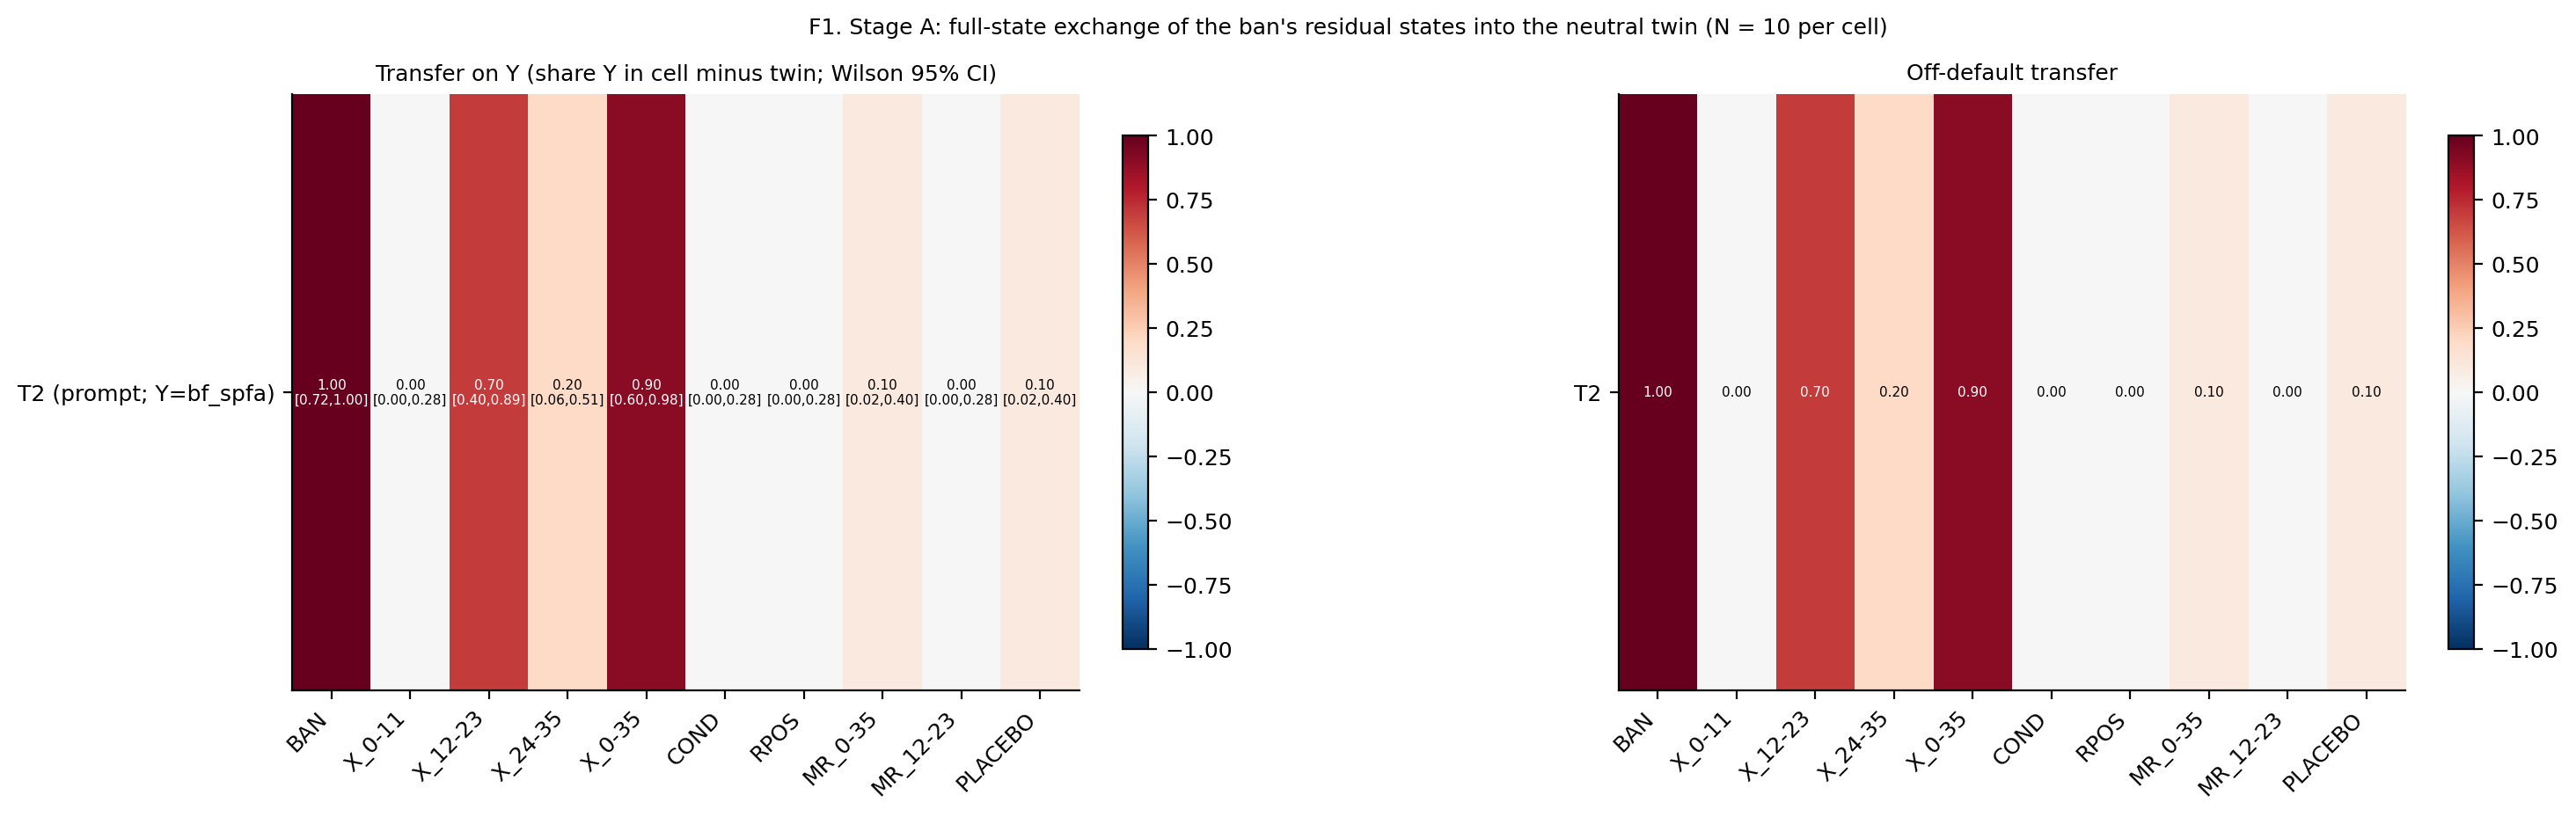

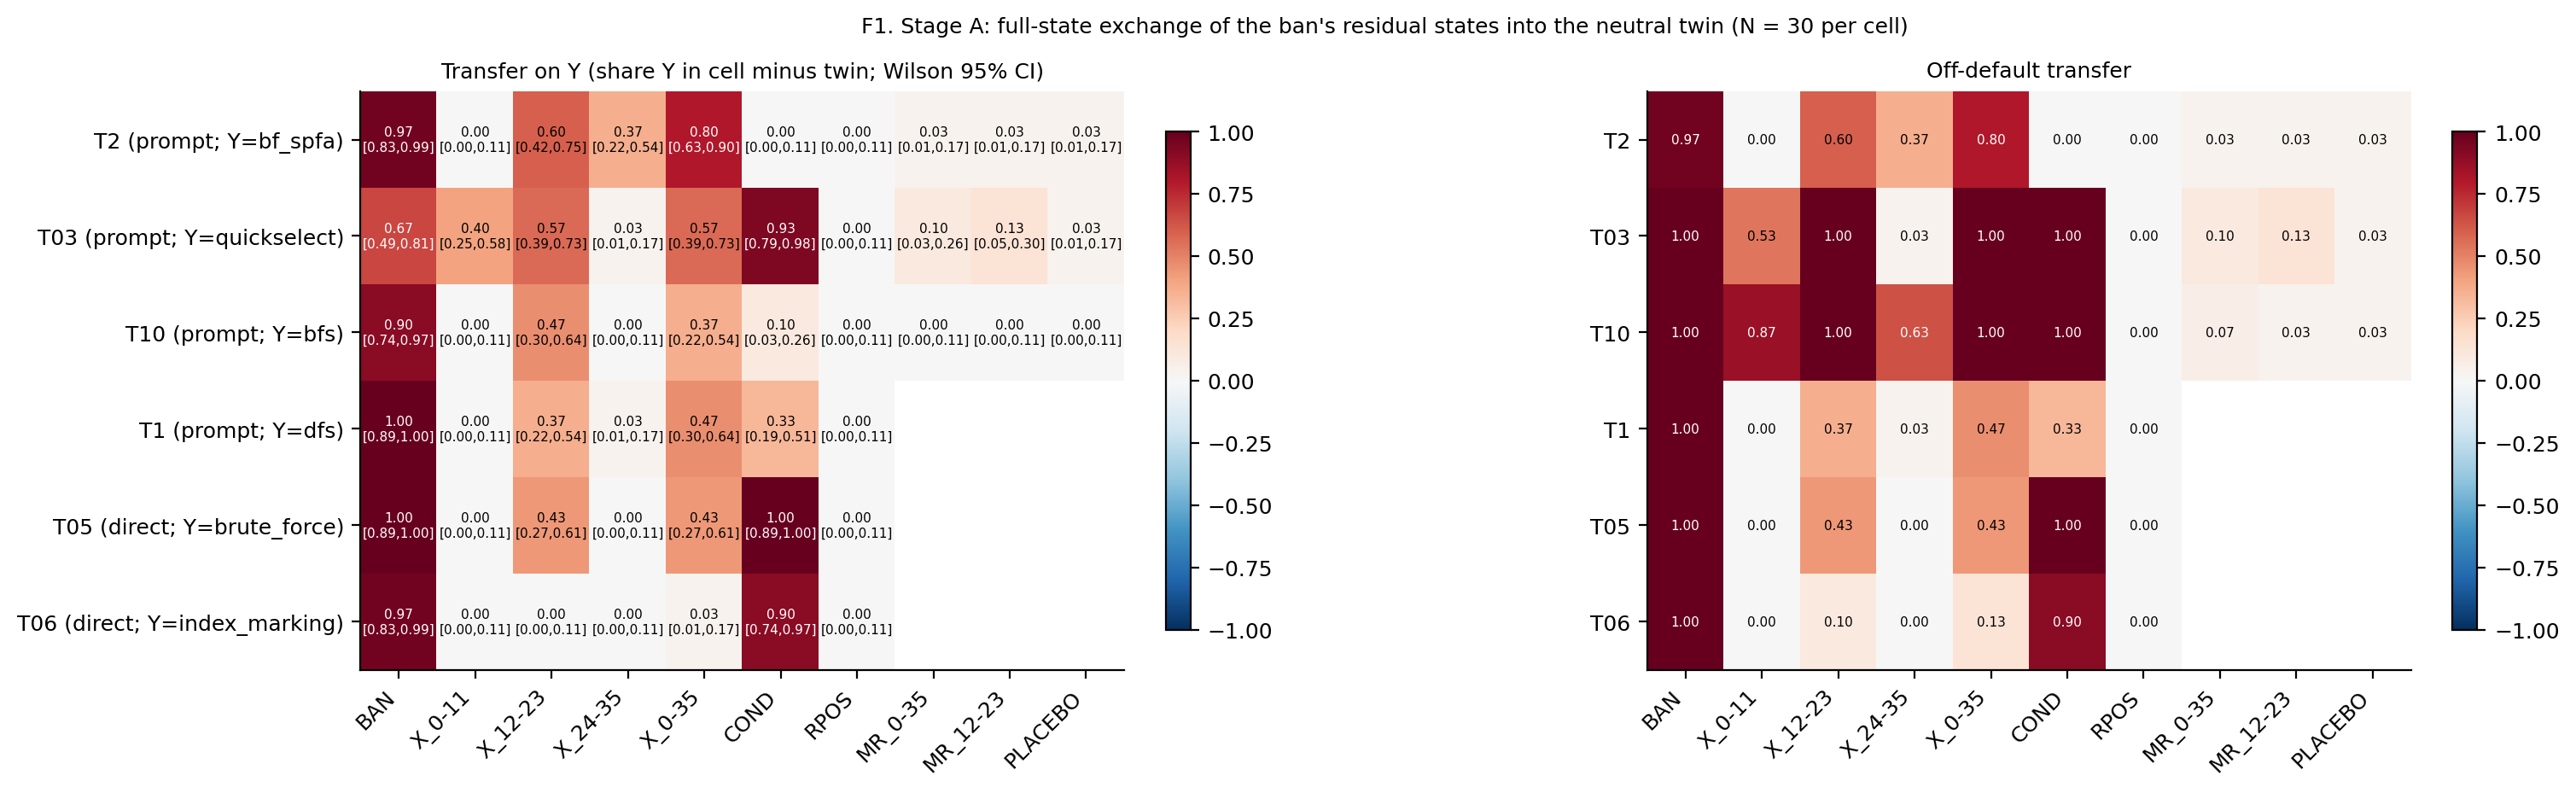

In [18]:
# ---- src/figures6.py (palette, style and save() verbatim; f1 with path/name arguments and a data-driven N) ----
# matplotlib.use("Agg")   # figures6.py renders headless; the notebook keeps its inline backend
OI = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#999999"]
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})
CELLS = ["BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "MR_0-35", "MR_12-23", "PLACEBO"]


def save(fig: plt.Figure, name: str) -> None:
    FIG_DIR.mkdir(exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)
    logger.info(f"figure {name}")


def f1(p: Path | None = None, name: str = "F1_stageA_transfer") -> None:
    p = p or RESULTS_DIR / "stage_a.json"   # figures6.py: p = RESULTS_DIR / "stage_a.json"
    if not p.exists():
        return
    a = read_json(p)["tasks"]
    tasks = [t for t in ("T2", "T03", "T10", "T1", "T05", "T06") if t in a]
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={"wspace": 0.55})
    for ax, key, title in ((axes[0], "transfer", "Transfer on Y (share Y in cell minus twin; Wilson 95% CI)"),
                           (axes[1], "off_default_transfer", "Off-default transfer")):
        M = np.full((len(tasks), len(CELLS)), np.nan)
        for i, t in enumerate(tasks):
            for j, c in enumerate(CELLS):
                v = a[t]["cells"].get(c, {}).get(key)
                if v is not None:
                    M[i, j] = v
        im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
        for i, t in enumerate(tasks):
            for j, c in enumerate(CELLS):
                cc = a[t]["cells"].get(c)
                if cc is None:
                    continue
                txt = f"{M[i, j]:.2f}"
                if key == "transfer":
                    lo, hi = cc["Y_ci95_wilson"]
                    txt += f"\n[{lo - a[t]['TWIN']['Y_share']:.2f},{hi - a[t]['TWIN']['Y_share']:.2f}]"
                ax.text(j, i, txt, ha="center", va="center", fontsize=5.5,
                        color="white" if abs(M[i, j]) > 0.6 else "black")
        ax.set_xticks(range(len(CELLS)), CELLS, rotation=45, ha="right")
        ax.set_yticks(range(len(tasks)), [f"{t} ({a[t]['route_class_iter2_3']}; Y={a[t]['Y']})" if key == "transfer"
                                          else t for t in tasks])
        ax.set_title(title, fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.03)
    n_cell = max(c["n"] for t in tasks for c in a[t]["cells"].values())   # notebook: N from the data (was "30")
    fig.suptitle(f"F1. Stage A: full-state exchange of the ban's residual states into the neutral twin (N = {n_cell} "
                 f"per cell)", fontsize=9)
    save(fig, name)


f1()   # this notebook's recomputation
write_json(RESULTS_DIR / "stage_a_reported.json", data["metadata"]["reported_stage_a"])
f1(RESULTS_DIR / "stage_a_reported.json", "F1_stageA_transfer_reported")   # the run's reported results (= published F1)
display(Image(filename=str(FIG_DIR / "F1_stageA_transfer.png"), width=1100))
display(Image(filename=str(FIG_DIR / "F1_stageA_transfer_reported.png"), width=1100))

## 11. Results at a glance: the paired slots behind every number

**Left:** every demo program in a grid of **cells × CRN slots**. Each square is one generated program, coloured by its labelled algorithm; × marks a program that fails the task's unit tests. All squares in a column share the same random numbers, which is why each cell can be tested against the twin slot by slot.

**Right:** the recomputed Y share per cell (N = `N_SLOTS`, Clopper-Pearson 95%) beside the value the full run reported (N = 30). The table below repeats the key numbers.

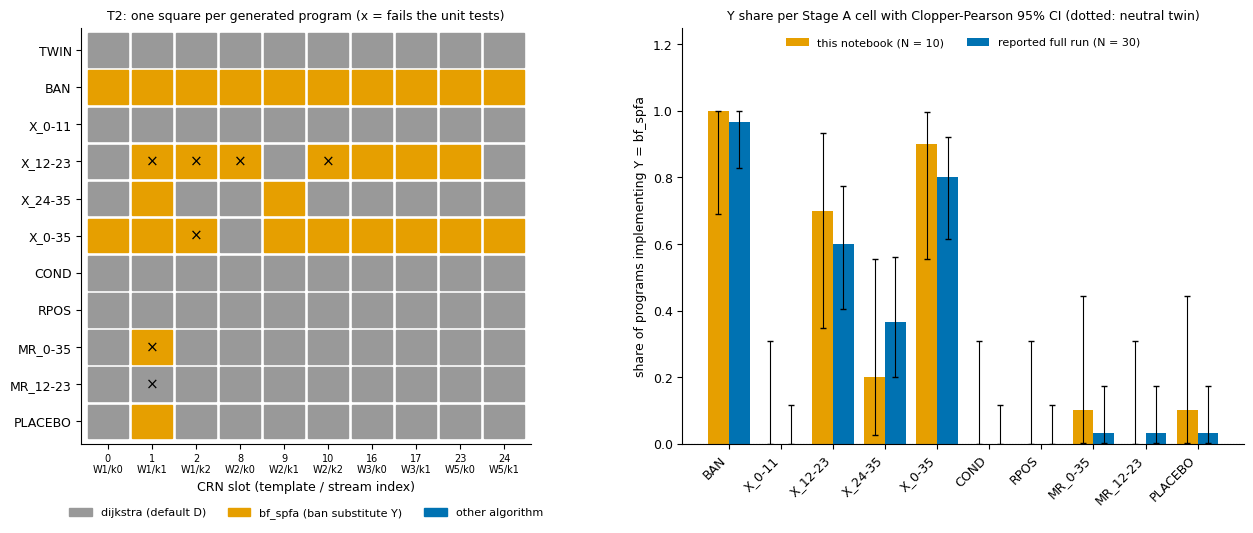

**T2** (D = dijkstra, Y = bf_spfa): twin Y share 0.00 (this notebook), 0.00 (reported)

| cell | Y k/n (this notebook) | transfer | McNemar b:c, exact p | reported transfer (N = 30) | reported b:c, Holm p |
|---|---|---|---|---|---|
| BAN | 10/10 | 1.00 | 10:0, 0.002 | 0.97 | 29:0, 1.5e-08 |
| X_0-11 | 0/10 | 0.00 | 0:0, 1.000 | 0.00 | 0:0, 1.000 |
| X_12-23 | 7/10 | 0.70 | 7:0, 0.016 | 0.60 | 18:0, 4.6e-05 |
| X_24-35 | 2/10 | 0.20 | 2:0, 0.500 | 0.37 | 11:0, 0.006 |
| X_0-35 | 9/10 | 0.90 | 9:0, 0.004 | 0.80 | 24:0, 7.2e-07 |
| COND | 0/10 | 0.00 | 0:0, 1.000 | 0.00 | 0:0, 1.000 |
| RPOS | 0/10 | 0.00 | 0:0, 1.000 | 0.00 | 0:0, 1.000 |
| MR_0-35 | 1/10 | 0.10 | 1:0, 1.000 | 0.03 | 1:0, 1.000 |
| MR_12-23 | 0/10 | 0.00 | 0:0, 1.000 | 0.03 | 1:0, 1.000 |
| PLACEBO | 1/10 | 0.10 | 1:0, 1.000 | 0.03 | 1:0, 1.000 |

In [19]:
# Notebook addition: the paired-slot grid and the recomputed vs reported Y share per cell
T_SHOW = "T2"
dem, rep = a["tasks"][T_SHOW], data["metadata"]["reported_stage_a"]["tasks"][T_SHOW]
arms = ["TWIN"] + list(A_ARMS)
col = {DEFAULT6[T_SHOW]: OI[8], Y6[T_SHOW]: OI[1]}   # default grey, Y orange, any other algorithm blue
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.3})
for i, arm in enumerate(arms):
    c_ = cell(rows, T_SHOW, arm)
    for j, s in enumerate(DEMO_SLOTS):
        if s in c_:
            ax0.add_patch(plt.Rectangle((j - 0.45, i - 0.45), 0.9, 0.9, color=col.get(c_[s]["label"], OI[5])))
            if not c_[s]["passed"]:
                ax0.text(j, i, "×", ha="center", va="center", fontsize=11)
ax0.set_xlim(-0.6, len(DEMO_SLOTS) - 0.4)
ax0.set_ylim(len(arms) - 0.4, -0.6)
ax0.set_xticks(range(len(DEMO_SLOTS)), [f"{s}\n{SLOT_MAP[s][0]}/k{SLOT_MAP[s][1]}" for s in DEMO_SLOTS], fontsize=7)
ax0.set_yticks(range(len(arms)), arms)
ax0.set_xlabel("CRN slot (template / stream index)")
ax0.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=OI[8]), plt.Rectangle((0, 0), 1, 1, color=OI[1]),
                    plt.Rectangle((0, 0), 1, 1, color=OI[5])],
           labels=[f"{DEFAULT6[T_SHOW]} (default D)", f"{Y6[T_SHOW]} (ban substitute Y)", "other algorithm"],
           loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False, fontsize=8)
ax0.set_title(f"{T_SHOW}: one square per generated program (x = fails the unit tests)", fontsize=9)
x_ = np.arange(len(A_ARMS))
for off, src, lab, cc in ((-0.2, dem, f"this notebook (N = {len(DEMO_SLOTS)})", OI[1]),
                          (0.2, rep, "reported full run (N = 30)", OI[5])):
    ys = np.array([src["cells"][k]["Y_share"] for k in A_ARMS])
    ci = np.array([src["cells"][k]["Y_ci95_cp"] for k in A_ARMS])
    ax1.bar(x_ + off, ys, 0.4, color=cc, label=lab, yerr=[ys - ci[:, 0], ci[:, 1] - ys], capsize=2,
            error_kw={"lw": 0.8})
ax1.axhline(dem["TWIN"]["Y_share"], color="grey", ls=":", lw=0.8)
ax1.set_xticks(x_, A_ARMS, rotation=45, ha="right")
ax1.set_ylabel(f"share of programs implementing Y = {Y6[T_SHOW]}")
ax1.set_ylim(0, 1.25)
ax1.legend(frameon=False, fontsize=8, loc="upper center", ncol=2)
ax1.set_title("Y share per Stage A cell with Clopper-Pearson 95% CI (dotted: neutral twin)", fontsize=9)
plt.show()

display(Markdown(
    f"**{T_SHOW}** (D = {DEFAULT6[T_SHOW]}, Y = {Y6[T_SHOW]}): twin Y share {f(dem['TWIN']['Y_share'])} "
    f"(this notebook), {f(rep['TWIN']['Y_share'])} (reported)\n\n"
    "| cell | Y k/n (this notebook) | transfer | McNemar b:c, exact p | reported transfer (N = 30) | "
    "reported b:c, Holm p |\n|---|---|---|---|---|---|\n" + "\n".join(
        f"| {k} | {round(dem['cells'][k]['Y_share'] * dem['cells'][k]['n'])}/{dem['cells'][k]['n']} | "
        f"{f(dem['cells'][k]['transfer'])} | {dem['cells'][k]['mcnemar_vs_twin']['b_Y_only_cell']}:"
        f"{dem['cells'][k]['mcnemar_vs_twin']['c_Y_only_twin']}, {f(dem['cells'][k]['mcnemar_vs_twin']['p'], 3)} | "
        f"{f(rep['cells'][k]['transfer'])} | {rep['cells'][k]['mcnemar_vs_twin']['b_Y_only_cell']}:"
        f"{rep['cells'][k]['mcnemar_vs_twin']['c_Y_only_twin']}, {f(rep['cells'][k]['mcnemar_vs_twin']['p_holm'], 3)} |"
        for k in A_ARMS)))

## 12. What the exchange does to the program: one paired slot

Three programs from the **same CRN slot**, so they share every random number:
- the neutral twin;
- the full ban;
- the twin with the ban's spec states written in at all blocks (`X_0-35`).

The cell picks the first demo slot in which `X_0-35` writes Y. In `X_0-35` the condition sentence of the twin is unchanged; only the residual states at the task-specification positions carry the ban.

In [20]:
# Notebook addition: the programs of one paired slot (the first demo slot in which X_0-35 writes Y)
codes = {r["sample_id"]: r.get("code") for r in LABEL_ROWS}
xc = cell(rows, T_SHOW, "X_0-35")
s_show = next((s for s in DEMO_SLOTS if s in xc and xc[s]["label"] == Y6[T_SHOW]), DEMO_SLOTS[0])
for arm in ("TWIN", "BAN", "X_0-35"):
    r = cell(rows, T_SHOW, arm)[s_show]
    print(f"===== {arm} | slot {s_show} ({SLOT_MAP[s_show][0]}, stream {SLOT_MAP[s_show][1]}) | label {r['label']} | "
          f"passes the unit tests: {r['passed']} =====")
    print(codes.get(sample_id(T_SHOW, arm, s_show)) or "(program text is not part of full_method_out.json)")

===== TWIN | slot 0 (W1, stream 0) | label dijkstra | passes the unit tests: True =====
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    
    graph = [[] for _ in range(n)]
    for u, v, w in edges:
        graph[u].append((v, w))
    
    dist = [float('inf')] * n
    dist[s] = 0
    heap = [(0, s)]
    
    while heap:
        current_dist, u = heapq.heappop(heap)
        if current_dist > dist[u]:
            continue
        for v, weight in graph[u]:
            if dist[v] > dist[u] + weight:
                dist[v] = dist[u] + weight
                heapq.heappush(heap, (dist[v], v))
    
    return dist[t] if dist[t] != float('inf') else -1

===== BAN | slot 0 (W1, stream 0) | label bf_spfa | passes the unit tests: True =====
def solve(n, edges, s, t):
    if s == t:
        return 0
    
    from collections import deque
    
    # Build adjacency list
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    
    #

## Summary

- **The Stage A pattern of the full run is visible in a handful of recorded programs.** Writing the ban's task-specification states into the neutral twin (`X_0-35`, mostly blocks 12-23) moves T2 from Dijkstra to Bellman-Ford/SPFA, in the same slots where the full ban does (slot IIA). Blocks 0-11 alone, the condition-span KV splice (`COND`) and the read position (`RPOS`) move nothing. The matched-norm random exchange and the placebo twin barely move it. On T2, therefore, the ban is *read into the task-spec states during the prompt* (the prompt route) rather than fetched later from the condition tokens.
- **Small N.** With ten slots per cell the intervals are wide, and one slot moves a share by 0.1. The full run's N = 30 table (section 8) is the reference.
- **The checks agree.** The audit's stdlib re-derivation matches the analysis code on every Stage A check. The swapped-label placebo loses the effect, as it must.
- **Checked at full scale.** With `FULL_DATA` pointed at the artifact's `full_method_out.json` (1,530 programs, six tasks × 30 slots), this notebook reproduced every value of the artifact's published `results/stage_a.json` (1,316 numbers, 0 differences). Excluded from the comparison: the N = 50 twin share and the exp16 U6 comparison, which need rows outside the Stage A dataset. The audit then reported 210 checks and 0 mismatches.

**Scaling back to the original run**
- `N_SLOTS = 10` (all of the demo data) and `N_PERM = 2000` (the audit's original).
- `FULL_DATA = "<path to the artifact's full_method_out.json>"` reruns Stage A on all six tasks × 30 slots. This reproduces the published tables and the committed verdicts: P1 NOT SUPPORTED, because T05's spec states also transfer 0.43; the route check, PLACEBO and MR predictions hold.
- `RUN_FULL_PIPELINE = True`, inside the artifact repository with its `.venv`, reruns `method.py` itself. `STAGES_TO_RUN = ["analysis", "figures", "audit"]` runs on CPU from the recorded rows. `["all"]` regenerates every program and needs one 16 GB GPU for about 2.7 GPU-hours, plus OpenRouter keys for the label judges.